# 多产品多资源约束库存系统的小批量 SGD 补充实验

## tl;dr

12 个配对种子的结果显示：稳态下，批量由 1 增至 100 时，解析梯度批方差从 27.13 降至 0.32，目标更新从约 1,192 次降至 12 次，策略循环时间从 0.27 秒降至 0.05 秒；累计 Regret 则从 390 增至 2,120。非平稳场景中，自适应 50→1 平均在变化后 6.7 期触发，变化后前 100 期成本为 27.05，恢复时间约 37 期；固定批量 50 和 100 在 600 期后均未达到恢复标准。标准 SGD 的总体 Regret 和恢复时间仍最低。以上是本设定下的合成实验结果，不构成对原论文理论结论的复现。

## Context & Methods

实验沿用 Lyu 等（2025）第 3 节的“固定目标库存、累计工作期梯度、批末投影更新”元策略，以及第 5 节的多产品、多资源约束结构。目标低于现有库存时，采用原文的过渡子问题：在满足资源约束和不低于当前库存的条件下，投影到最接近目标的可执行库存向量。

标准 SGD 每个工作期更新一次（B=1）；固定小批量组为 B=10、50、100。所有组共用目标函数、初始库存、学习率、约束条件及每个种子的需求路径。每批完成后按平均梯度执行一次投影更新。过渡期不收集梯度，与论文元策略保持一致。

非平稳场景在中点改变 Poisson 需求均值。自适应批量 SGD 是本补充实验的扩展设想：常态批量为 50；EWMA 需求变化检测（α=0.18，阈值 2.00）触发后，将批量缩为 1 并持续 60 期，再恢复为 50。变化检测使用模拟器完整需求观测，这是额外假设，不属于原论文算法或其理论保证。

### Key Assumptions

- 三种产品需求在给定时期内独立服从 Poisson 分布；需求均值在稳态实验中固定，在动态实验中只发生一次突变。
- 仿真器为分析目的保留完整需求路径。梯度更新本身通过销量与是否缺货构造，等价于原文的单样本次梯度信号；自适应检测器额外读取完整需求。
- Regret 使用真实需求分布下的单期期望成本差，算法不使用该真值；平均库存成本使用实现路径上的实际成本。
- 过渡库存向量通过凸投影计算；目标更新次数只统计完整批次更新。


### 1. 实验参数

下方参数统一控制两个场景。重复运行使用配对随机种子，使不同算法在同一重复中面对完全相同的需求路径。

In [1]:
import json
import math
import time
from pathlib import Path
from functools import lru_cache

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown

# Reproducible design
SEEDS = list(range(20261101, 20261113))  # 12 paired repetitions
HORIZON = 1200
CHANGE_POINT = HORIZON // 2
ETA = 0.03
INITIAL_STOCK = np.array([7.0, 8.0, 7.0])

PRODUCTS = ["产品 A", "产品 B", "产品 C"]
HOLDING_COST = np.array([1.2, 1.5, 1.0])
LOST_SALES_COST = np.array([7.0, 5.5, 6.0])
RESOURCE_USE = np.array([
    [1.0, 1.0, 1.0],
    [0.7, 1.4, 0.6],
])
RESOURCE_CAPACITY = np.array([25.0, 24.0])

PRE_MEAN = np.array([6.0, 7.5, 5.5])
POST_MEAN = np.array([10.0, 5.0, 9.0])
FIXED_BATCHES = [1, 10, 50, 100]
ADAPTIVE_BASE_BATCH = 50
ADAPTIVE_BATCH = 1
ADAPTIVE_HORIZON = 60
EWMA_ALPHA = 0.18
EWMA_THRESHOLD = 2.00
DETECTOR_COOLDOWN = 120

font_path = Path("C:/Windows/Fonts/msyh.ttc")
if font_path.exists():
    font_manager.fontManager.addfont(str(font_path))
    PLOT_FONT = font_manager.FontProperties(fname=str(font_path)).get_name()
else:
    PLOT_FONT = "DejaVu Sans"
COLORS = {"B=1": "#2563EB", "B=10": "#0F766E", "B=50": "#D97706", "B=100": "#7C3AED", "Adaptive 50→1": "#DC2626"}
plt.rcParams.update({"font.family": PLOT_FONT, "figure.figsize": (8.2, 4.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.22, "font.size": 10})

print(f"重复次数={len(SEEDS)} | 期数={HORIZON} | 学习率 η={ETA} | 初始库存={INITIAL_STOCK.tolist()}")
print("资源约束矩阵 A=")
print(RESOURCE_USE)
print("容量 r=", RESOURCE_CAPACITY)


重复次数=12 | 期数=1200 | 学习率 η=0.03 | 初始库存=[7.0, 8.0, 7.0]
资源约束矩阵 A=
[[1.  1.  1. ]
 [0.7 1.4 0.6]]
容量 r= [25. 24.]


### 2. 可行域、目标函数和解析梯度

每期成本为持有成本与缺货损失之和。Poisson 分布下的期望成本和期望次梯度通过有限尾概率求和计算；该计算只用于评估 Regret 和检测偏差，不提供给在线算法。

In [2]:
@lru_cache(maxsize=64)
def poisson_table(mean, tail_sd=12, extra=20):
    """Numerically stable finite Poisson PMF table with negligible omitted tail."""
    max_d = int(math.ceil(mean + tail_sd * math.sqrt(mean + 1.0) + extra))
    probs = np.empty(max_d + 1, dtype=float)
    probs[0] = math.exp(-mean)
    for d in range(1, max_d + 1):
        probs[d] = probs[d - 1] * mean / d
    probs /= probs.sum()
    demand = np.arange(max_d + 1, dtype=float)
    cdf = np.cumsum(probs)
    cdf_demand = np.cumsum(probs * demand)
    return demand, probs, cdf, cdf_demand


def project_halfspaces(point, normals, limits, tol=1e-10, max_cycles=250):
    """Dykstra projection onto {y: normals @ y <= limits}."""
    x = np.asarray(point, dtype=float).copy()
    corrections = np.zeros_like(normals)
    norm_sq = np.sum(normals * normals, axis=1)
    for _ in range(max_cycles):
        before = x.copy()
        for j, (normal, limit) in enumerate(zip(normals, limits)):
            candidate = x + corrections[j]
            violation = float(normal @ candidate - limit)
            projected = candidate - max(0.0, violation) / norm_sq[j] * normal
            corrections[j] = candidate - projected
            x = projected
        if np.linalg.norm(x - before) < tol and np.max(normals @ x - limits) < 10 * tol:
            break
    return x


GAMMA_NORMALS = np.vstack([RESOURCE_USE, -np.eye(3)])
GAMMA_LIMITS = np.concatenate([RESOURCE_CAPACITY, np.zeros(3)])

def project_gamma(point):
    return project_halfspaces(point, GAMMA_NORMALS, GAMMA_LIMITS)


def project_transition(target, on_hand):
    """Closest feasible inventory not below on-hand inventory (paper's transition QP)."""
    normals = np.vstack([RESOURCE_USE, -np.eye(3)])
    limits = np.concatenate([RESOURCE_CAPACITY, -np.asarray(on_hand, dtype=float)])
    return project_halfspaces(target, normals, limits)


def expected_cost(stock, mean):
    total = 0.0
    for i, y in enumerate(stock):
        demand, probs, cdf, cdf_demand = poisson_table(float(mean[i]))
        k = min(int(math.floor(y)), len(demand) - 1)
        p_le = cdf[k]
        e_d_le = cdf_demand[k]
        holding = y * p_le - e_d_le
        shortage = mean[i] - e_d_le - y * (1.0 - p_le)
        total += HOLDING_COST[i] * holding + LOST_SALES_COST[i] * shortage
    return float(total)


def expected_gradient(stock, mean):
    gradient = np.empty(3, dtype=float)
    for i, y in enumerate(stock):
        demand, probs, cdf, _ = poisson_table(float(mean[i]))
        # The estimator uses -b at equality y=d, so use P(D < y).
        less_k = int(math.ceil(y)) - 1
        p_less = cdf[less_k] if less_k >= 0 else 0.0
        gradient[i] = HOLDING_COST[i] * p_less - LOST_SALES_COST[i] * (1.0 - p_less)
    return gradient


def oracle_for_mean(mean):
    """Projected gradient solve used only for evaluation, with a convergence check."""
    y = project_gamma(INITIAL_STOCK)
    step = 0.04
    for _ in range(4000):
        candidate = project_gamma(y - step * expected_gradient(y, mean))
        if np.linalg.norm(candidate - y) < 1e-9:
            y = candidate
            break
        y = candidate
    return y, expected_cost(y, mean)


assert np.max(RESOURCE_USE @ INITIAL_STOCK - RESOURCE_CAPACITY) <= 1e-9
ORACLES = {tuple(PRE_MEAN): oracle_for_mean(PRE_MEAN), tuple(POST_MEAN): oracle_for_mean(POST_MEAN)}
print("稳态最优库存与期望成本:", ORACLES[tuple(PRE_MEAN)])
print("突变后最优库存与期望成本:", ORACLES[tuple(POST_MEAN)])


稳态最优库存与期望成本: (array([8.00349191, 9.00496951, 7.99153857]), 14.806486988149372)
突变后最优库存与期望成本: (array([10.98342598,  5.00261883,  9.01395519]), 22.489229849316253)


### 3. 仿真器和在线算法

算法按工作期计数批量；当目标库存不可直接执行时，过渡投影给出可执行库存，并暂停梯度采集。自适应规则在观测到变化后清空未完成批次，以一个新样本更新目标，再在 60 个日历期内逐次更新。

In [3]:
def generate_demands(seed, nonstationary=False):
    rng = np.random.default_rng(seed)
    if nonstationary:
        means = np.repeat(PRE_MEAN[None, :], HORIZON, axis=0)
        means[CHANGE_POINT:] = POST_MEAN
        return np.vstack([rng.poisson(row) for row in means])
    return rng.poisson(PRE_MEAN, size=(HORIZON, 3))


def run_policy(demands, batch_size, adaptive=False, nonstationary=False):
    target = INITIAL_STOCK.copy()
    on_hand = INITIAL_STOCK.copy()
    gradient_buffer = []
    completed_batches = []
    stock_path = np.empty((HORIZON, 3))
    transition_flags = np.zeros(HORIZON, dtype=bool)
    update_flags = np.zeros(HORIZON, dtype=bool)
    batch_path = np.full(HORIZON, batch_size, dtype=int)
    alarm_times = []
    dropped_gradients = 0
    reference_mean = PRE_MEAN.copy()
    ewma = np.zeros(3)
    rapid_until = -1
    last_alarm = -DETECTOR_COOLDOWN

    start = time.perf_counter()
    for t in range(HORIZON):
        current_batch = ADAPTIVE_BATCH if adaptive and t <= rapid_until else batch_size
        batch_path[t] = current_batch
        if np.all(on_hand <= target + 1e-9):
            implemented = target.copy()
        else:
            implemented = project_transition(target, on_hand)
        transition_flags[t] = np.linalg.norm(implemented - target) > 1e-7
        stock_path[t] = implemented

        demand = demands[t]
        working = not transition_flags[t]
        if working:
            sales = np.minimum(demand, implemented)
            sample_gradient = np.where(sales < implemented - 1e-12,
                                       HOLDING_COST, -LOST_SALES_COST)
        else:
            sample_gradient = None

        alarm = False
        if adaptive:
            standardized = (demand - reference_mean) / np.sqrt(np.maximum(reference_mean, 1.0))
            ewma = (1.0 - EWMA_ALPHA) * ewma + EWMA_ALPHA * standardized
            if (t >= 30 and t - last_alarm >= DETECTOR_COOLDOWN
                    and np.linalg.norm(ewma) > EWMA_THRESHOLD):
                alarm = True
                alarm_times.append(t)
                last_alarm = t
                rapid_until = t + ADAPTIVE_HORIZON - 1
                dropped_gradients += len(gradient_buffer)
                gradient_buffer = []
                left = max(0, t - 29)
                reference_mean = np.mean(demands[left:t + 1], axis=0)
                ewma[:] = 0.0

        if adaptive and alarm:
            current_batch = ADAPTIVE_BATCH
            batch_path[t] = current_batch

        if working:
            gradient_buffer.append(sample_gradient)
            if len(gradient_buffer) >= current_batch:
                batch_gradient = np.mean(gradient_buffer, axis=0)
                completed_batches.append((target.copy(), batch_gradient.copy(), current_batch, t))
                target = project_gamma(target - ETA * batch_gradient)
                update_flags[t] = True
                gradient_buffer = []

        on_hand = np.maximum(implemented - demand, 0.0)
    algorithm_seconds = time.perf_counter() - start

    # Score realized cost and true-distribution pseudo-regret outside the timed policy loop.
    costs = (HOLDING_COST[None, :] * np.maximum(stock_path - demands, 0.0)
             + LOST_SALES_COST[None, :] * np.maximum(demands - stock_path, 0.0)).sum(axis=1)
    regret = np.empty(HORIZON)
    for t in range(HORIZON):
        mean = POST_MEAN if nonstationary and t >= CHANGE_POINT else PRE_MEAN
        regret[t] = expected_cost(stock_path[t], mean) - ORACLES[tuple(mean)][1]

    batch_errors = []
    batch_variances = []
    for batch_target, batch_gradient, used_batch, end_period in completed_batches:
        mean = POST_MEAN if nonstationary and end_period >= CHANGE_POINT else PRE_MEAN
        true_gradient = expected_gradient(batch_target, mean)
        batch_errors.append(float(np.sum((batch_gradient - true_gradient) ** 2)))
        p_less = np.zeros(3)
        for i, y in enumerate(batch_target):
            _, _, cdf, _ = poisson_table(float(mean[i]))
            k = int(math.ceil(y)) - 1
            p_less[i] = cdf[k] if k >= 0 else 0.0
        one_sample_trace = float(np.sum((HOLDING_COST + LOST_SALES_COST) ** 2
                                        * p_less * (1.0 - p_less)))
        batch_variances.append(one_sample_trace / used_batch)

    return {
        "costs": costs,
        "regret": regret,
        "stock": stock_path,
        "transitions": transition_flags,
        "updates": update_flags,
        "batch_path": batch_path,
        "runtime_seconds": algorithm_seconds,
        "gradient_error": np.asarray(batch_errors),
        "gradient_variance": np.asarray(batch_variances),
        "alarms": alarm_times,
        "dropped_gradients": dropped_gradients,
    }


def method_specs(nonstationary=False):
    specs = [(f"B={b}", b, False) for b in FIXED_BATCHES]
    if nonstationary:
        specs.append(("Adaptive 50→1", ADAPTIVE_BASE_BATCH, True))
    return specs


### 4. 运行配对随机种子实验

每个固定批量和每个种子均读取相同需求矩阵。自适应批量仅在非平稳组启用。

In [4]:
stationary_runs = {name: [] for name, _, _ in method_specs(False)}
nonstationary_runs = {name: [] for name, _, _ in method_specs(True)}

for seed in SEEDS:
    stationary_demands = generate_demands(seed, nonstationary=False)
    dynamic_demands = generate_demands(seed, nonstationary=True)
    for name, batch, adaptive in method_specs(False):
        stationary_runs[name].append(run_policy(stationary_demands, batch, adaptive=False, nonstationary=False))
    for name, batch, adaptive in method_specs(True):
        nonstationary_runs[name].append(run_policy(dynamic_demands, batch, adaptive=adaptive, nonstationary=True))

print(f"完成 {len(SEEDS)} 个配对种子；稳态 {sum(map(len, stationary_runs.values()))} 次运行，"
      f"非平稳 {sum(map(len, nonstationary_runs.values()))} 次运行。")


完成 12 个配对种子；稳态 48 次运行，非平稳 60 次运行。


## Data

本实验不使用企业数据。需求、成本、资源消耗和容量均由配置单元明确设定。下表展示实验中的产品和共享资源；所有需求流在同一种子下跨算法配对。

In [5]:
print("产品成本参数：")
for i, product in enumerate(PRODUCTS):
    print(f"{product}: 持有成本={HOLDING_COST[i]:.1f}, 缺货损失={LOST_SALES_COST[i]:.1f}, "
          f"稳态需求均值={PRE_MEAN[i]:.1f}, 突变后均值={POST_MEAN[i]:.1f}")
print("\n资源可行性：库存向量 y 满足 A y ≤ r")
for j, label in enumerate(["总仓储容量", "配送能力"]):
    print(f"{label}: 系数={RESOURCE_USE[j].tolist()}, 容量={RESOURCE_CAPACITY[j]:.1f}")
print("\n初始库存资源使用量:", (RESOURCE_USE @ INITIAL_STOCK).round(2).tolist())


产品成本参数：
产品 A: 持有成本=1.2, 缺货损失=7.0, 稳态需求均值=6.0, 突变后均值=10.0
产品 B: 持有成本=1.5, 缺货损失=5.5, 稳态需求均值=7.5, 突变后均值=5.0
产品 C: 持有成本=1.0, 缺货损失=6.0, 稳态需求均值=5.5, 突变后均值=9.0

资源可行性：库存向量 y 满足 A y ≤ r
总仓储容量: 系数=[1.0, 1.0, 1.0], 容量=25.0
配送能力: 系数=[0.7, 1.4, 0.6], 容量=24.0

初始库存资源使用量: [22.0, 20.3]


## Results

### 稳态需求下的批量规模比较

累计 Regret 是每期真实期望成本减去同一需求分布下的最优可行库存成本，再对路径求和。平均库存成本是实现需求路径上的实际每期成本。梯度估计方差同时报告已完成批次的经验平方误差和按当前目标分布计算的理论单次梯度方差 / 批量。

In [6]:
def mean_ci(values):
    values = np.asarray(values, dtype=float)
    mean = float(np.mean(values))
    se = float(np.std(values, ddof=1) / math.sqrt(len(values))) if len(values) > 1 else 0.0
    return mean, 1.96 * se


def stationary_summary(runs):
    rows = []
    for name, reps in runs.items():
        run_regret = [float(np.sum(r["regret"])) for r in reps]
        run_cost = [float(np.mean(r["costs"])) for r in reps]
        run_var = [float(np.mean(r["gradient_error"])) if len(r["gradient_error"]) else np.nan for r in reps]
        run_theory_var = [float(np.mean(r["gradient_variance"])) if len(r["gradient_variance"]) else np.nan for r in reps]
        run_updates = [int(np.sum(r["updates"])) for r in reps]
        run_transitions = [int(np.sum(r["transitions"])) for r in reps]
        run_time = [r["runtime_seconds"] for r in reps]
        metrics = [run_regret, run_cost, run_var, run_theory_var, run_updates, run_transitions, run_time]
        stats = [mean_ci(x) for x in metrics]
        rows.append({"方法": name, "累计 Regret 均值": stats[0][0], "Regret 95% 半宽": stats[0][1],
                     "平均库存成本": stats[1][0], "成本 95% 半宽": stats[1][1],
                     "梯度批均方误差": stats[2][0], "解析批方差": stats[3][0],
                     "目标更新次数": stats[4][0], "过渡期数": stats[5][0],
                     "运行时间秒": stats[6][0]})
    return rows


def print_table(rows, columns, digits=3):
    widths = {col: max(len(col), max(len(f"{r[col]:.{digits}f}") if isinstance(r[col], (float, np.floating)) else len(str(r[col])) for r in rows)) for col in columns}
    print(" | ".join(col.ljust(widths[col]) for col in columns))
    print("-+-".join("-" * widths[col] for col in columns))
    for row in rows:
        cells = [f"{row[col]:.{digits}f}" if isinstance(row[col], (float, np.floating)) else str(row[col]) for col in columns]
        print(" | ".join(cells[i].ljust(widths[col]) for i, col in enumerate(columns)))

stationary_rows = stationary_summary(stationary_runs)
print_table(stationary_rows, ["方法", "累计 Regret 均值", "Regret 95% 半宽", "平均库存成本", "梯度批均方误差", "解析批方差", "目标更新次数", "过渡期数", "运行时间秒"])


方法    | 累计 Regret 均值 | Regret 95% 半宽 | 平均库存成本 | 梯度批均方误差 | 解析批方差  | 目标更新次数   | 过渡期数  | 运行时间秒
------+--------------+---------------+--------+---------+--------+----------+-------+------
B=1   | 390.117      | 20.330        | 15.110 | 27.088  | 27.132 | 1192.167 | 7.833 | 0.275
B=10  | 516.101      | 37.877        | 15.216 | 2.849   | 2.742  | 119.417  | 0.667 | 0.074
B=50  | 1767.956     | 40.368        | 16.229 | 0.642   | 0.633  | 23.917   | 0.083 | 0.050
B=100 | 2120.379     | 19.704        | 16.511 | 0.318   | 0.320  | 12.000   | 0.000 | 0.048


### 稳态成本、Regret 与梯度方差

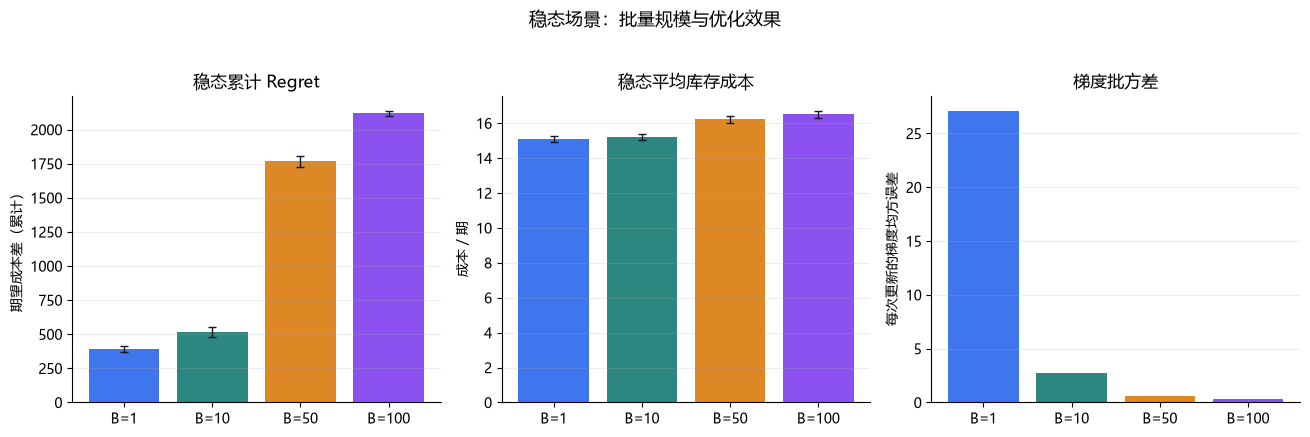

95% 区间误差线以跨种子均值 ± 1.96×标准误表示；梯度方差是解析估计，省略误差线。


In [7]:
names = list(stationary_runs)
regret_means = [next(r["累计 Regret 均值"] for r in stationary_rows if r["方法"] == n) for n in names]
regret_ci = [next(r["Regret 95% 半宽"] for r in stationary_rows if r["方法"] == n) for n in names]
cost_means = [next(r["平均库存成本"] for r in stationary_rows if r["方法"] == n) for n in names]
cost_ci = [next(r["成本 95% 半宽"] for r in stationary_rows if r["方法"] == n) for n in names]
variance_means = [next(r["解析批方差"] for r in stationary_rows if r["方法"] == n) for n in names]

fig, axes = plt.subplots(1, 3, figsize=(13.2, 4.2))
for ax, vals, errs, title, ylabel in [
    (axes[0], regret_means, regret_ci, "稳态累计 Regret", "期望成本差（累计）"),
    (axes[1], cost_means, cost_ci, "稳态平均库存成本", "成本 / 期"),
    (axes[2], variance_means, [0] * len(names), "梯度批方差", "每次更新的梯度均方误差"),
]:
    x = np.arange(len(names))
    ax.bar(x, vals, color=[COLORS[n] for n in names], alpha=0.88)
    if any(errs):
        ax.errorbar(x, vals, yerr=errs, fmt="none", ecolor="#111827", capsize=3, lw=1)
    ax.set_xticks(x, names)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(axis="x", visible=False)
fig.suptitle("稳态场景：批量规模与优化效果", y=1.03, fontsize=13)
fig.tight_layout()
plt.show()

print("95% 区间误差线以跨种子均值 ± 1.96×标准误表示；梯度方差是解析估计，省略误差线。")


### 非平稳需求变化下的表现

平均动态 Regret 和平均成本同时覆盖变化前后。另报告变化后前 100 期的成本差，以及“恢复时间”：首次出现连续 20 期滚动的真实期望成本差不超过突变后最优期望成本的 10%；若未达到则记为未恢复。

In [8]:
def recovery_time(run, threshold_fraction=0.10, window=20):
    gaps = run["regret"][CHANGE_POINT:]
    threshold = threshold_fraction * ORACLES[tuple(POST_MEAN)][1]
    if len(gaps) < window:
        return np.nan
    rolling = np.convolve(gaps, np.ones(window) / window, mode="valid")
    hits = np.flatnonzero(rolling <= threshold)
    return float(hits[0]) if len(hits) else np.nan


def dynamic_summary(runs):
    rows = []
    for name, reps in runs.items():
        total_regret = [float(np.sum(r["regret"])) for r in reps]
        total_cost = [float(np.mean(r["costs"])) for r in reps]
        post_cost = [float(np.mean(r["costs"][CHANGE_POINT:CHANGE_POINT + 100])) for r in reps]
        post_regret = [float(np.sum(r["regret"][CHANGE_POINT:])) for r in reps]
        recoveries = np.asarray([recovery_time(r) for r in reps], dtype=float)
        post_alarms = [next((a for a in r["alarms"] if a >= CHANGE_POINT), None) for r in reps]
        false_alarm_count = sum(a < CHANGE_POINT for r in reps for a in r["alarms"])
        delays = [a - CHANGE_POINT for a in post_alarms if a is not None]
        rows.append({"方法": name,
                     "累计 Regret 均值": mean_ci(total_regret)[0], "Regret 95% 半宽": mean_ci(total_regret)[1],
                     "平均库存成本": mean_ci(total_cost)[0], "成本 95% 半宽": mean_ci(total_cost)[1],
                     "变化后前100期成本": mean_ci(post_cost)[0], "变化后累计 Regret": mean_ci(post_regret)[0],
                     "恢复期数": float(np.nanmean(recoveries)) if np.any(np.isfinite(recoveries)) else np.nan,
                     "未恢复种子数": int(np.sum(~np.isfinite(recoveries))),
                     "目标更新次数": float(np.mean([np.sum(r["updates"]) for r in reps])),
                     "过渡期数": float(np.mean([np.sum(r["transitions"]) for r in reps])),
                     "运行时间秒": float(np.mean([r["runtime_seconds"] for r in reps])),
                     "检测延迟": float(np.mean(delays)) if delays else np.nan,
                     "变化前误报次数": int(false_alarm_count)})
    return rows

dynamic_rows = dynamic_summary(nonstationary_runs)
print("动态效果（每项均为 12 个配对随机种子的均值；Regret 与成本含 95% 均值区间半宽）：")
print_table(dynamic_rows, ["方法", "累计 Regret 均值", "Regret 95% 半宽", "平均库存成本", "成本 95% 半宽", "变化后前100期成本", "变化后累计 Regret", "恢复期数", "未恢复种子数"])
print("\n计算与检测诊断：")
print_table(dynamic_rows, ["方法", "目标更新次数", "过渡期数", "运行时间秒", "检测延迟", "变化前误报次数"])


动态效果（每项均为 12 个配对随机种子的均值；Regret 与成本含 95% 均值区间半宽）：
方法            | 累计 Regret 均值 | Regret 95% 半宽 | 平均库存成本 | 成本 95% 半宽 | 变化后前100期成本 | 变化后累计 Regret | 恢复期数    | 未恢复种子数
--------------+--------------+---------------+--------+-----------+------------+--------------+---------+-------
B=1           | 705.013      | 24.680        | 19.141 | 0.175     | 25.818     | 489.980      | 32.833  | 0     
B=10          | 3161.875     | 60.221        | 21.144 | 0.207     | 33.634     | 2693.768     | 348.917 | 0     
B=50          | 8515.804     | 88.036        | 25.592 | 0.258     | 40.350     | 7451.490     | nan     | 12    
B=100         | 10975.183    | 63.903        | 27.649 | 0.280     | 41.897     | 9822.485     | nan     | 12    
Adaptive 50→1 | 1712.993     | 62.005        | 19.967 | 0.213     | 27.050     | 648.679      | 36.833  | 0     

计算与检测诊断：
方法            | 目标更新次数   | 过渡期数  | 运行时间秒 | 检测延迟  | 变化前误报次数
--------------+----------+-------+-------+-------+--------
B=1           | 1192.083 | 7.917

### 需求变化后的成本轨迹

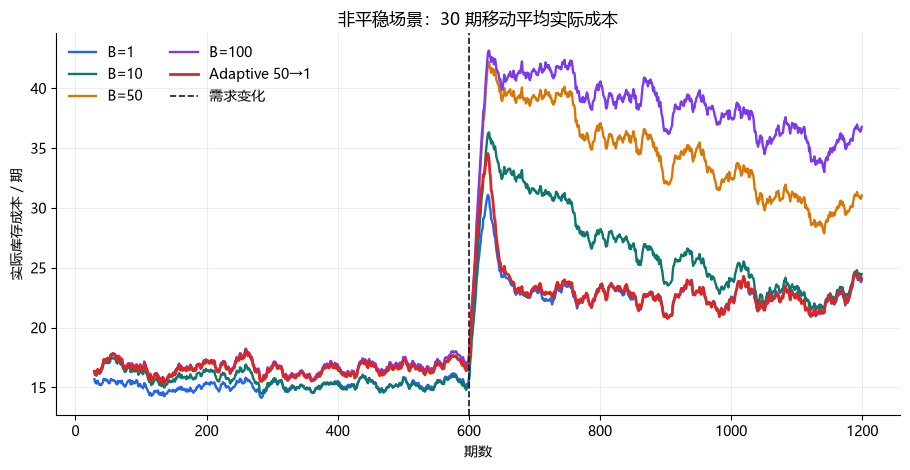

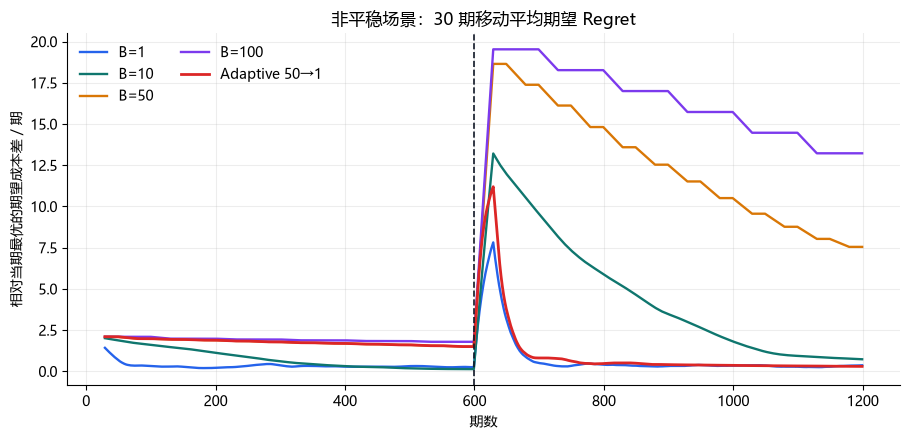

In [9]:
fig, ax = plt.subplots(figsize=(9.2, 4.8))
window = 30
for name, reps in nonstationary_runs.items():
    mean_cost = np.mean([r["costs"] for r in reps], axis=0)
    smooth = np.convolve(mean_cost, np.ones(window) / window, mode="valid")
    x = np.arange(window - 1, HORIZON)
    ax.plot(x, smooth, label=name, color=COLORS[name], lw=2 if name == "Adaptive 50→1" else 1.7)
ax.axvline(CHANGE_POINT, color="#111827", ls="--", lw=1.2, label="需求变化")
ax.set_title("非平稳场景：30 期移动平均实际成本")
ax.set_xlabel("期数")
ax.set_ylabel("实际库存成本 / 期")
ax.legend(ncol=2, frameon=False)
fig.tight_layout()
plt.show()

# Plot expected-cost regret gaps for pooled mean paths; each policy sees paired random paths.
fig, ax = plt.subplots(figsize=(9.2, 4.5))
for name, reps in nonstationary_runs.items():
    mean_gap = np.mean([r["regret"] for r in reps], axis=0)
    smooth = np.convolve(mean_gap, np.ones(window) / window, mode="valid")
    ax.plot(np.arange(window - 1, HORIZON), smooth, label=name, color=COLORS[name], lw=2 if name == "Adaptive 50→1" else 1.7)
ax.axvline(CHANGE_POINT, color="#111827", ls="--", lw=1.2)
ax.set_title("非平稳场景：30 期移动平均期望 Regret")
ax.set_xlabel("期数")
ax.set_ylabel("相对当期最优的期望成本差 / 期")
ax.legend(ncol=2, frameon=False)
fig.tight_layout()
plt.show()


## Takeaways

- **稳态结果呈现清晰的降噪与滞后权衡。** 从 B=1 到 B=100，解析批方差从 27.13 降至 0.32，经验批梯度均方误差从 27.09 降至 0.32；目标更新次数约从 1,192 次降至 12 次，策略循环时间约下降 5.8 倍。同期累计 Regret 从 390 增至 2,120，平均库存成本从 15.11 升至 16.51。批量 10 的成本差较小，但累计 Regret 已高于 B=1。
- **需求突变放大了固定大批量的响应迟滞。** B=50 和 B=100 的 12 个随机种子在剩余 600 期内均未达到预先规定的恢复标准；B=10 平均需要约 349 期恢复。
- **自适应批量在响应与计算量之间取得折中。** 平均检测延迟为 6.7 期，12 次运行无突变前误报；变化后前 100 期成本为 27.05，平均约 37 期达到恢复标准。相较固定批量 50，其动态累计 Regret 从 8,516 降至 1,713，变化后前 100 期成本从 40.35 降至 27.05。标准 SGD 的累计 Regret 为 705、恢复约需 33 期，仍优于自适应方案，但平均更新次数和策略循环时间分别约为自适应方案的 8.5 倍和 2.8 倍。

这些结果只支持本合成场景中的机制比较。自适应批量的表现依赖 EWMA 阈值、突变幅度和 60 期快速响应窗口；需要在不同变化幅度、变化方向、假警率目标和相关需求下进一步做敏感性分析。\n\n### Reference\n\nLyu, J., Xie, J., Yuan, S., & Zhou, Y. (2025). A Minibatch Stochastic Gradient Descent-Based Learning Metapolicy for Inventory Systems with Myopic Optimal Policy. *Management Science, 71*(7), 5572–5588. https://doi.org/10.1287/mnsc.2023.00920

In [10]:
# Compact evidence payload for the accompanying explanation document.
summary_payload = {
    "seeds": SEEDS,
    "horizon": HORIZON,
    "change_point": CHANGE_POINT,
    "eta": ETA,
    "pre_mean": PRE_MEAN.tolist(),
    "post_mean": POST_MEAN.tolist(),
    "pre_oracle": {"stock": ORACLES[tuple(PRE_MEAN)][0].tolist(), "cost": ORACLES[tuple(PRE_MEAN)][1]},
    "post_oracle": {"stock": ORACLES[tuple(POST_MEAN)][0].tolist(), "cost": ORACLES[tuple(POST_MEAN)][1]},
    "stationary": stationary_rows,
    "dynamic": dynamic_rows,
    "dynamic_alarm_count": {name: int(sum(len(run["alarms"]) for run in reps)) for name, reps in nonstationary_runs.items()},
}
def json_safe(value):
    if isinstance(value, dict):
        return {key: json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(item) for item in value]
    if isinstance(value, (float, np.floating)) and not math.isfinite(float(value)):
        return None
    if isinstance(value, np.integer):
        return int(value)
    return value

print("RESULTS_JSON:" + json.dumps(json_safe(summary_payload), ensure_ascii=False, allow_nan=False))


RESULTS_JSON:{"seeds": [20261101, 20261102, 20261103, 20261104, 20261105, 20261106, 20261107, 20261108, 20261109, 20261110, 20261111, 20261112], "horizon": 1200, "change_point": 600, "eta": 0.03, "pre_mean": [6.0, 7.5, 5.5], "post_mean": [10.0, 5.0, 9.0], "pre_oracle": {"stock": [8.003491914842808, 9.00496951031922, 7.99153857483797], "cost": 14.806486988149372}, "post_oracle": {"stock": [10.983425975759834, 5.002618833958715, 9.013955190281449], "cost": 22.489229849316253}, "stationary": [{"方法": "B=1", "累计 Regret 均值": 390.1171134573144, "Regret 95% 半宽": 20.329578508295484, "平均库存成本": 15.109675640702692, "成本 95% 半宽": 0.17061925334453304, "梯度批均方误差": 27.088390252227423, "解析批方差": 27.132464598677966, "目标更新次数": 1192.1666666666667, "过渡期数": 7.833333333333333, "运行时间秒": 0.2747177833322591}, {"方法": "B=10", "累计 Regret 均值": 516.1009902943209, "Regret 95% 半宽": 37.8771772274325, "平均库存成本": 15.215588428472229, "成本 95% 半宽": 0.17338524828173651, "梯度批均方误差": 2.8492029342572027, "解析批方差": 2.742062183880041, 